In [14]:
import numpy as np
import matplotlib.pyplot as plt

DELTA = 0.0
U = 6.0
V = 2.0

In [15]:
from ed.config import Config
from ed.basis import SpinfulBasis
from ed.lattice import Lattice
from ed.hamiltonian import Hamiltonian
from ed.ed_solver import EDSolver

EDcfg = Config()
EDlatt = Lattice(EDcfg)
EDbasis = SpinfulBasis(EDcfg, EDlatt)
EDham = Hamiltonian(EDcfg, EDbasis, EDlatt)
EDham.build(DELTA, U, V)
EDsolver = EDSolver(EDcfg, EDham)

Egs_exact, _ = EDsolver.ground_state(DELTA, U, V)
eloc_exact = Egs_exact/EDlatt.n_sites

In [16]:
from vmc.config import Config
from vmc.lattice import Lattice
from vmc.hamiltonian import Hamiltonian
from vmc.wavefunction import SlaterJastrow
from vmc.optimizer import optimize

cfg = Config()
latt = Lattice(cfg)
print(' N sites: ', latt.n_sites)
ham = Hamiltonian(cfg, latt, DELTA, U, V)
wf = SlaterJastrow(cfg, latt, 
                   free={'delta': 1, 'm': 1, 'js_ch': 'rnd', 'js_sp': 'rnd'},
                   fixed={'t2': 0.2, 'phi': 0.5})
data = optimize(cfg, wf, ham)

 N sites:  12


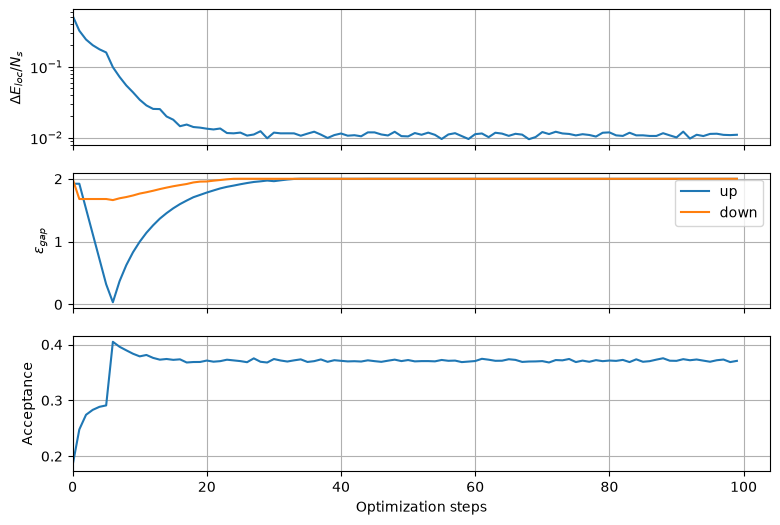

In [17]:
eloc = data['e_loc']
gap = data['mf_gap']
acc = data['acc']

fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(abs(eloc - eloc_exact)); ax[0].set_ylabel(r'$\Delta E_{loc}/N_s$'); ax[0].set_yscale('log')
ax[1].plot(gap[:,0], label='up'); ax[1].set_ylabel(r'$\epsilon_{gap}$')
ax[1].plot(gap[:,1], label='down'); ax[1].set_ylabel(r'$\epsilon_{gap}$')
ax[1].legend()
ax[2].plot(acc); ax[2].set_ylabel('Acceptance')
for a in ax:
    a.grid(); a.set_xlim(left=0)
    if a == ax[-1]:
        a.set_xlabel('Optimization steps')
plt.show()

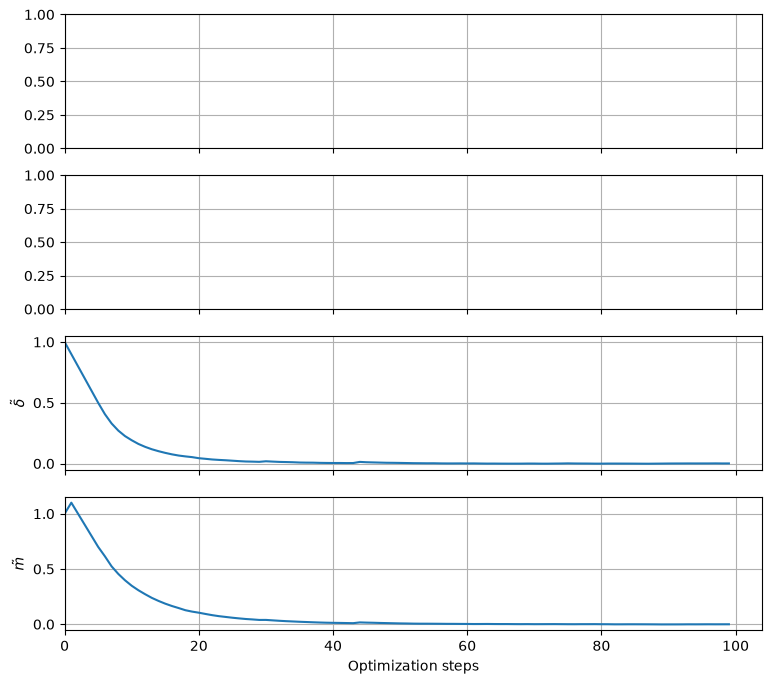

In [18]:
fig, ax = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
#ax[0].plot(data['t2']); ax[0].set_ylabel(r'$\tilde{t}_2$')
#ax[1].plot(data['phi']); ax[1].set_ylabel(r'$\tilde{\phi}$')
ax[2].plot(data['delta']); ax[2].set_ylabel(r'$\tilde{\delta}$')
ax[3].plot(data['m']); ax[3].set_ylabel(r'$\tilde{m}$')
for a in ax:
    a.grid(); a.set_xlim(left=0)
    if a == ax[-1]:
        a.set_xlabel('Optimization steps')
        
plt.show()

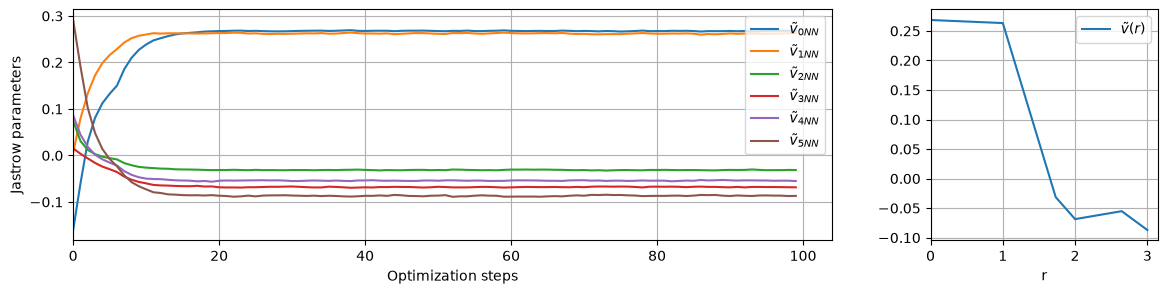

In [19]:
vpot = data['js_ch']
fig, ax = plt.subplots(1, 2, figsize=(14, 3), width_ratios=(1,0.3))
for d in range(len(vpot[0,:])):
    ax[0].plot(vpot[:,d], label=rf'$\tilde{{v}}_{{{d}NN}}$')
    ax[0].set_ylabel('Jastrow parameters'); ax[0].set_xlabel('Optimization steps')
ax[1].plot(latt.bond_dist, vpot[-1,:], label=r'$\tilde{v}(r)$'); ax[1].set_xlabel('r')
for a in ax:
    a.grid(); a.set_xlim(left=0); a.legend()

plt.show()

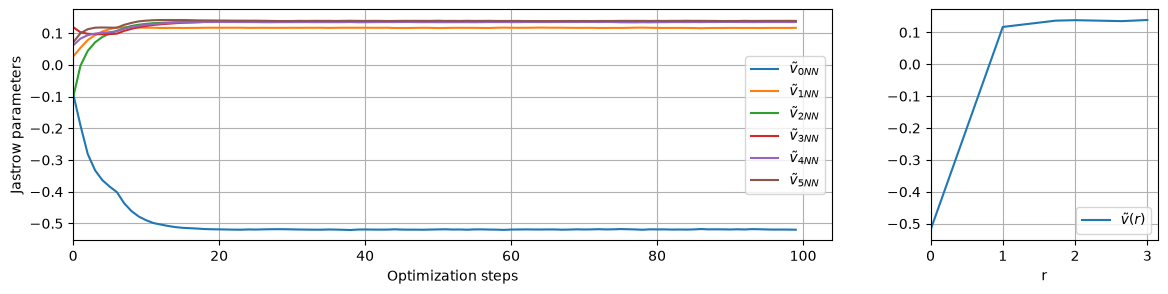

In [20]:
vpot = data['js_sp']
fig, ax = plt.subplots(1, 2, figsize=(14, 3), width_ratios=(1,0.3))
for d in range(len(vpot[0,:])):
    ax[0].plot(vpot[:,d], label=rf'$\tilde{{v}}_{{{d}NN}}$')
    ax[0].set_ylabel('Jastrow parameters'); ax[0].set_xlabel('Optimization steps')
ax[1].plot(latt.bond_dist, vpot[-1,:], label=r'$\tilde{v}(r)$'); ax[1].set_xlabel('r')
for a in ax:
    a.grid(); a.set_xlim(left=0); a.legend()

plt.show()

In [21]:
from vmc.sampler import measure
res = measure(cfg, wf, ham, n_meas=500)
print(res['cdw'])
print(res['sdw'])

(np.float64(0.6609843749999991), np.float64(0.0018629294184716078))
(np.float64(0.8109114583333302), np.float64(0.0022911829267472194))


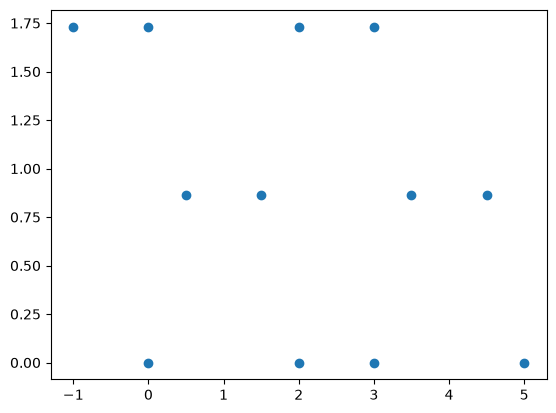

In [22]:
plt.scatter(latt.positions[:,0], latt.positions[:,1])
plt.show()